# 01 — Single-Sérsic mock fit

This notebook validates the minimal BayMorph inference workflow on a synthetic single-Sérsic galaxy.

Workflow:

1. build a noiseless Sérsic mock;
2. define a constant noise map;
3. fit flux, effective radius, and Sérsic index with `DynestyFitter`;
4. inspect posterior summaries and residuals.

This notebook is intentionally small and does not use FITS I/O. FITS workflows are introduced in Notebook 02.

## Imports

In [1]:
import matplotlib.pyplot as plt

from baymorph import (
    DynestyFitter,
    Parameter,
    ParameterSet,
    SersicModel,
    make_constant_noise_map,
    plot_data_model_residual,
)

## True model

In [2]:
true_parameters = {
    "flux": 1000.0,
    "re": 8.0,
    "n": 2.0,
    "q": 0.8,
    "theta": 0.0,
    "x0": 30.0,
    "y0": 30.0,
}

true_model = SersicModel(
    **true_parameters,
)

## Render mock image

In [3]:
data = true_model.render(
    shape=(60, 60),
)

noise = make_constant_noise_map(
    data.shape,
    sigma=1.0,
)

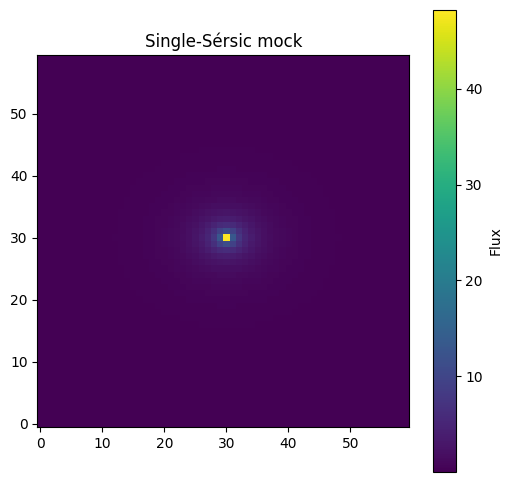

Total rendered flux: 999.9999999999999


In [4]:
plt.figure(figsize=(6, 6))
plt.imshow(
    data,
    origin="lower",
)
plt.colorbar(label="Flux")
plt.title("Single-Sérsic mock")
plt.show()

print("Total rendered flux:", data.sum())

## Model factory

In [5]:
def model_factory(
    flux,
    re,
    n,
):
    return SersicModel(
        flux=flux,
        re=re,
        n=n,
        q=true_parameters["q"],
        theta=true_parameters["theta"],
        x0=true_parameters["x0"],
        y0=true_parameters["y0"],
    )

## ParameterSet

In [6]:
parameters = ParameterSet(
    [
        Parameter(
            "flux",
            100.0,
            2000.0,
        ),
        Parameter(
            "re",
            2.0,
            20.0,
        ),
        Parameter(
            "n",
            0.5,
            8.0,
        ),
    ]
)

## Fit

In [7]:
fitter = DynestyFitter(
    model_factory=model_factory,
    data=data,
    noise=noise,
    parameters=parameters,
)

result = fitter.run(
    nlive=150,
    sample="rwalk",
    print_progress=True,
)

iter: 2004 | +150 | bound: 12 | nc: 1 | ncall: 39537 | eff(%):  5.469 | loglstar:   -inf < -3308.181 <    inf | logz: -3319.606 +/-  0.261 | dlogz:  0.001 >  0.159                                   

## Posterior summaries

In [8]:
for name in parameters.names:
    print("True", name + ":", true_parameters[name])
    print(result.summary(name))
    print()

True flux: 1000.0
{'q16': 965.4665358087769, 'median': 1007.0102381939416, 'q84': 1047.3990041217269}

True re: 8.0
{'q16': 7.605625816854104, 'median': 8.061885411042095, 'q84': 8.591824213323473}

True n: 2.0
{'q16': 1.9586345548773911, 'median': 2.003564809003746, 'q84': 2.050737909015889}



## Best-likelihood model and residual

In [9]:
best_parameters = result.best_parameters
best_parameters

{'flux': 1001.5468636665992, 're': 8.0112054221861, 'n': 2.0012805179932704}

(<Figure size 1800x600 with 6 Axes>,
 array([<Axes: title={'center': 'Data'}>,
        <Axes: title={'center': 'Model'}>,
        <Axes: title={'center': 'Residual'}>], dtype=object))

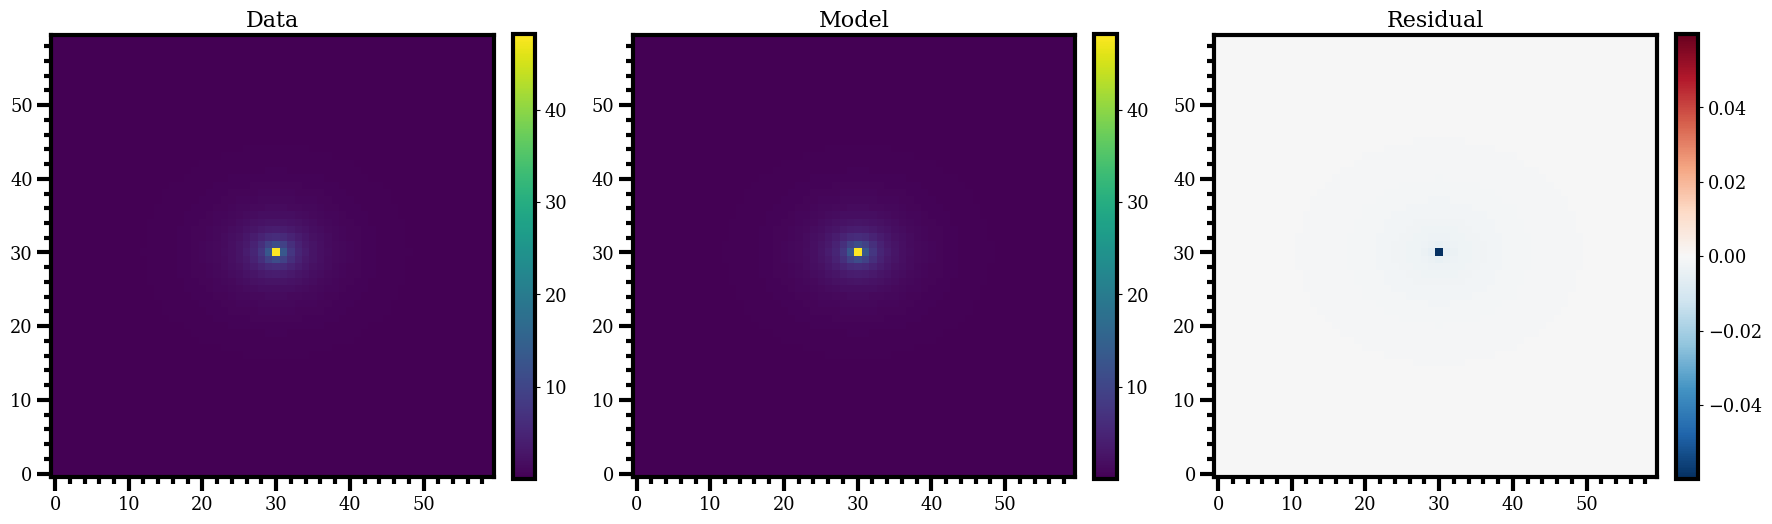

In [10]:
best_model = model_factory(
    flux=best_parameters["flux"],
    re=best_parameters["re"],
    n=best_parameters["n"],
)

best_image = best_model.render(
    shape=data.shape,
)

plot_data_model_residual(
    data,
    best_image,
)

## Recovery check

In [11]:
for name in parameters.names:
    true_value = true_parameters[name]
    recovered_value = best_parameters[name]
    error_percent = 100 * (recovered_value - true_value) / true_value

    print(f"{name}: true={true_value:.6g}, recovered={recovered_value:.6g}, error={error_percent:.3g}%")

flux: true=1000, recovered=1001.55, error=0.155%
re: true=8, recovered=8.01121, error=0.14%
n: true=2, recovered=2.00128, error=0.064%
